# Membuat nama dengan GRU (RNN) dari nol

Notebook ini melatih **GRU tingkat karakter** untuk membuat nama Indonesia baru. Spesifikasinya adalah [Name Generation using RNNs](https://github.com/florinpop17/app-ideas/blob/master/Projects/2-Intermediate/Name-Generator.md).

Seluruh model, termasuk forward, backpropagation through time, dan Adam, ditulis sendiri dengan numpy di [`name_rnn.py`](name_rnn.py), tanpa PyTorch atau TensorFlow.

Isi notebook:

1. melihat data nama,
2. memastikan gradien yang dihitung sendiri benar,
3. melatih model sambil memantau overfitting,
4. membandingkan model dengan pembanding sederhana,
5. membuat nama dari 2–3 huruf awal.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

import name_rnn as nr

plt.rcParams.update({"figure.figsize": (7, 4), "axes.spines.top": False, "axes.spines.right": False})
names = nr.load_names()
lengths = Counter(len(n) for n in names)
print(f"{len(names)} nama, panjang rata-rata {np.mean([len(n) for n in names]):.1f} huruf")
print("contoh:", ", ".join(names[::90]))

729 nama, panjang rata-rata 5.6 huruf
contoh: abdul, astrid, dimas, gibran, jono, naila, rian, susilo, zaenal


## 1. Data

Daftar 729 nama Indonesia di `data/nama-indonesia.txt` ditulis sendiri untuk project ini. Isinya campuran nama Jawa, Sunda, Bali, Batak, Minang, nama bernuansa Islam dan Kristen, serta nama modern. Semua nama ditulis dalam huruf kecil a–z.

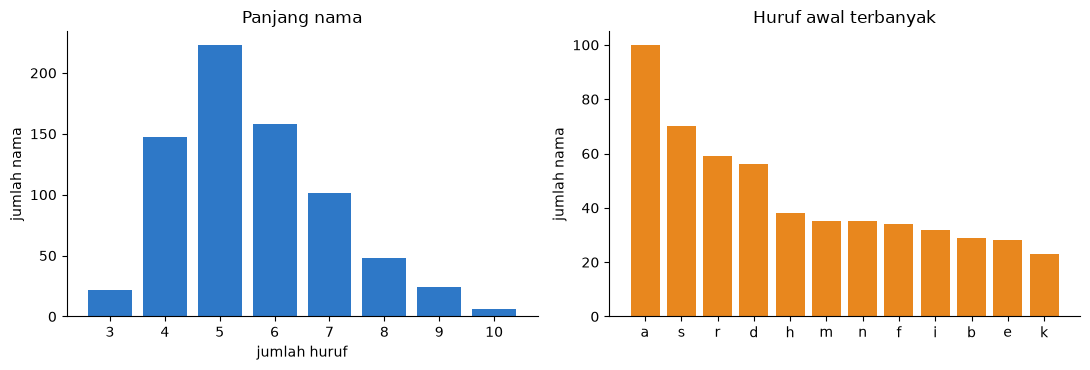

In [2]:
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.8))
xs = sorted(lengths)
a.bar(xs, [lengths[x] for x in xs], color="#2e78c7")
a.set(title="Panjang nama", xlabel="jumlah huruf", ylabel="jumlah nama")
first = Counter(n[0] for n in names).most_common(12)
b.bar([c for c, _ in first], [k for _, k in first], color="#e8871e")
b.set(title="Huruf awal terbanyak", ylabel="jumlah nama")
plt.tight_layout()

## 2. Memeriksa gradien

Backpropagation yang ditulis manual mudah salah. Karena itu gradien analitik dibandingkan dengan **gradien numerik** `(L(θ+ε) − L(θ−ε)) / 2ε` untuk *setiap* parameter, pada model kecil dengan 5 unit tersembunyi. Kalau rumusnya benar, selisih relatifnya sangat kecil (sekitar 1e-5 atau kurang).

In [3]:
tiny_names = ["ab", "ba", "abc", "c"]
tiny_vocab = nr.Vocab.from_names(tiny_names)
tiny = nr.GRU(len(tiny_vocab), hidden=5, seed=1)
x, y, mask = nr.make_batch(tiny_names, tiny_vocab)
_, grads = tiny.loss_and_grads(x, y, mask)
worst, checked = 0.0, 0
for key in nr.PARAMS:
    P = tiny.p[key]
    for i in np.ndindex(P.shape):
        old = P[i]
        P[i] = old + 1e-5
        up = tiny.loss_and_grads(x, y, mask)[0]
        P[i] = old - 1e-5
        down = tiny.loss_and_grads(x, y, mask)[0]
        P[i] = old
        numeric = (up - down) / 2e-5
        worst = max(worst, abs(numeric - grads[key][i]) / max(1e-8, abs(numeric) + abs(grads[key][i])))
        checked += 1
print(f"{checked} parameter diperiksa, selisih relatif terbesar: {worst:.1e}")

174 parameter diperiksa, selisih relatif terbesar: 3.6e-05


## 3. Melatih dan memantau overfitting

15% nama disisihkan sebagai **data validasi**, yang tidak pernah dipakai untuk belajar. Setiap 100 langkah, loss validasi diukur, dan model dengan loss validasi terendah yang disimpan (*early stopping*). Data ini kecil, jadi tanpa cara ini model akan menghafal nama-nama latih dan berhenti membuat nama baru.

Pengaturan: 48 unit tersembunyi, Adam dengan learning rate 0,003, weight decay 0,003, dan batch 64 nama. Pelatihan sengaja dibuat 6000 langkah supaya titik mulai overfitting terlihat.

loss validasi terbaik 2.181 di langkah 2900; di langkah 6000 loss latih 1.875, validasi 2.239


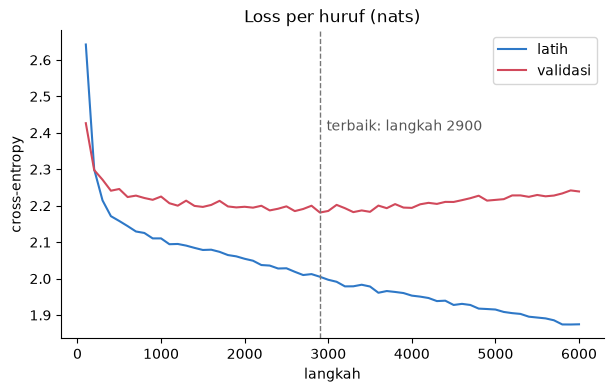

In [4]:
model, vocab, history = nr.train(names, steps=6000)
steps, train_loss, valid_loss = zip(*history)
best_step = model.best_step
plt.plot(steps, train_loss, label="latih", color="#2e78c7")
plt.plot(steps, valid_loss, label="validasi", color="#d1495b")
plt.axvline(best_step, color="#777", linestyle="--", linewidth=1)
plt.text(best_step + 80, max(valid_loss) - 0.02, f"terbaik: langkah {best_step}", color="#555")
plt.title("Loss per huruf (nats)")
plt.xlabel("langkah")
plt.ylabel("cross-entropy")
plt.legend()
print(f"loss validasi terbaik {min(valid_loss):.3f} di langkah {best_step}; "
      f"di langkah 6000 loss latih {train_loss[-1]:.3f}, validasi {valid_loss[-1]:.3f}")

Setelah titik terbaik, loss latih terus turun tetapi loss validasi naik lagi. Itu tanda model mulai menghafal. Model yang dipakai adalah model di titik terbaik.

## 4. Seberapa bagus?

Loss validasi dibandingkan dengan dua pembanding sederhana pada nama-nama validasi yang sama:

- **Acak seragam:** setiap simbol punya peluang sama, jadi lossnya `ln 26`. Ada 26 simbol: 25 huruf yang muncul di data (huruf *x* tidak ada di satu nama pun) ditambah tanda akhir nama.
- **Bigram:** peluang huruf berikutnya hanya dari satu huruf sebelumnya (dihitung dari data latih, dengan *add-one smoothing*).

In [5]:
train_names, valid_names = nr.split_names(names)
V = len(vocab)
counts = np.ones((V, V))
for n in train_names:
    seq = [0] + vocab.encode(n) + [0]
    for a, b in zip(seq, seq[1:]):
        counts[a, b] += 1
probs = counts / counts.sum(axis=1, keepdims=True)
bigram = -np.mean([np.log(probs[a, b]) for n in valid_names
                   for a, b in zip([0] + vocab.encode(n), vocab.encode(n) + [0])])
table = pd.DataFrame({"loss validasi (nats/huruf)": [np.log(V), bigram, nr.full_loss(model, vocab, valid_names)]},
                     index=["acak seragam", "bigram", "GRU"]).round(3)
table

,loss validasi (nats/huruf)
acak seragam,3.258
bigram,2.413
GRU,2.181


## 5. Membuat nama

Model diberi 2–3 huruf awal, lalu huruf berikutnya diambil acak sesuai peluang dari model sampai model memilih "akhir nama". **Temperature** mengatur keberanian: di bawah 1 model memilih huruf yang paling mungkin, di atas 1 pilihannya lebih acak.

Tanda `*` menandai nama yang **tidak ada** di data latih, jadi benar-benar nama baru.

In [6]:
known = set(names)
rows = {}
for prefix in ["ar", "sri", "wi", "dew", "ra", "nu", "bag", "kar"]:
    found = nr.generate_many(model, vocab, prefix, count=6, temperature=0.8, seed=1)
    rows[prefix] = [n.capitalize() + ("" if n in known else " *") for n in found]
pd.DataFrame(rows).T

,0,1,2,3,4,5
ar,Aritan *,Arisa *,Arangan *,Ari,Argia *,Aryus *
sri,Srilo *,Srita *,Srisag *,Srira *,Srisa *,Srian *
wi,Wintas *,Wini *,Winag *,Wilia *,Wifa *,Wiki *
dew,Dewis *,Dewra *,Dewi,Dewdi *,Dewan *,Dewiti *
ra,Ranuar *,Ralika *,Rangar *,Raman *,Rahil *,Rayus *
nu,Nuotita *,Nusim *,Nuslara *,Nudi *,Nugra *,Nuwri *
bag,Bagitan *,Bagesa *,Bagara *,Bagpan *,Bagel *,Bagmanus *
kar,Kariu *,Karui *,Karman *,Karil *,Karka *,Karama *


contoh temperature 0.4: anga, andi, saria, santi, pari, isan
contoh temperature 1.5: agti, ilbi, helkmudia, ydhskhp, qedmuah, rofonllaqt


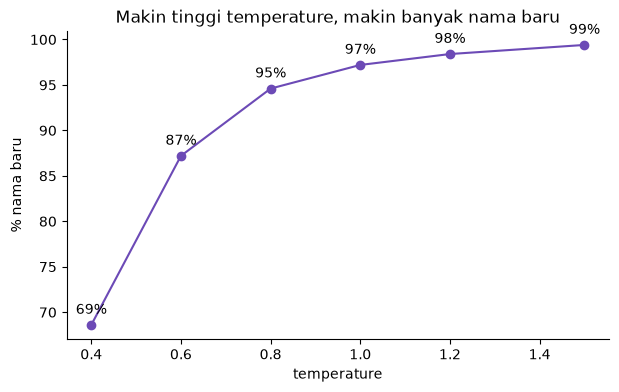

In [7]:
temps = [0.4, 0.6, 0.8, 1.0, 1.2, 1.5]
novel = []
for t in temps:
    rng = np.random.default_rng(0)
    sample = [nr.generate(model, vocab, "", t, rng) for _ in range(500)]
    novel.append(100 * np.mean([s not in known for s in sample]))
fig, ax = plt.subplots()
ax.plot(temps, novel, marker="o", color="#6c4ab6")
ax.set(title="Makin tinggi temperature, makin banyak nama baru", xlabel="temperature", ylabel="% nama baru")
for t, v in zip(temps, novel):
    ax.annotate(f"{v:.0f}%", (t, v), textcoords="offset points", xytext=(0, 8), ha="center")
print("contoh temperature 0.4:", ", ".join(nr.generate_many(model, vocab, "", 6, 0.4, seed=3)))
print("contoh temperature 1.5:", ", ".join(nr.generate_many(model, vocab, "", 6, 1.5, seed=3)))

## Kesimpulan

- **Gradien benar:** gradien yang ditulis sendiri cocok dengan gradien numerik.
- **Dibanding pembanding:** lihat tabel di bagian 4 untuk seberapa jauh GRU menurunkan loss validasi dibanding bigram.
- **Batas kualitas:** dengan hanya 729 nama, model cepat menghafal. Early stopping dan weight decay menjaganya tetap membuat nama baru, tetapi sebagian hasilnya masih terdengar janggal. Data yang lebih banyak adalah cara paling efektif untuk memperbaikinya.
- **Temperature:** temperature rendah menghasilkan nama yang lebih wajar tetapi lebih sering mengulang nama latih. Temperature tinggi menghasilkan lebih banyak nama baru, tetapi lebih sering terdengar asing.

Pakai dari terminal: `python name_rnn.py --prefix ar -n 5`.